# Week 09 — Algebraic Reconstruction: solving for the $\mu$'s

Last week we saw that a radiograph is a **projection** — the line integral of the linear
attenuation coefficient $\mu$ along a beam. This week we do what **Hounsfield's EMI scanner** did:
treat each **pencil X-ray beam** as one **Beer–Lambert equation** and *solve the linear system* for
every $\mu$ inside a hypothetical **4×4 image** (16 unknowns).

For a single ray through a chain of pixels of width $\Delta x$:
$$I = I_0\,\exp\!\Big(-\sum_i \mu_i\,\Delta x\Big)\;\Longrightarrow\;
p \equiv -\ln\!\frac{I}{I_0} = \sum_i \mu_i\,\Delta x.$$
The measured projection $p$ is a **weighted sum of the $\mu$'s** on the ray's path. Stacking one such
equation per ray gives a linear system $A\,\boldsymbol\mu = \mathbf{p}$, where each row of $A$ holds the
**path length** of that ray through each pixel. With enough rays (in enough orientations) the system
becomes solvable and we recover the image.

**How many equations?** Just as fitting a straight line $y=\beta_0+\beta_1x$ (two unknowns) needs two
points, solving for 16 unknown $\mu$'s needs **at least 16 independent** equations; more than 16 gives
a least-squares best fit. Hounsfield's **EMI scanner** did exactly this at scale — about **180 angles
× 160 measurements** each — to solve for the $\mu$'s across a 2-D slice.

**Plan**
1. Build a known 4×4 phantom (the ground-truth $\mu$ map) and simulate measurements.
2. Warm up on a tiny **2×2 image (4 unknowns)** solved directly and by least squares.
3. Horizontal + vertical rays only → show the system is **rank-deficient** (not enough information).
4. Add **diagonal** projections → rank 15 of 16 → **direct least-squares** solution.
5. Expose the leftover **null-space "ghost"** that one set of views cannot resolve.
6. Reconstruct the same image **iteratively** with the **ART / Kaczmarz** row-action method.
7. Add realistic **photon (Poisson) noise** and see how the reconstruction degrades.

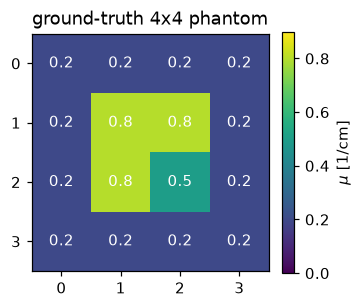

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
plt.rcParams["figure.dpi"] = 110

N = 4                                  # 4x4 image -> 16 unknown mu's

# Ground-truth attenuation map [1/cm]: soft-tissue background (0.2) + a dense 'bone' core
mu_true = np.array([
    [0.20, 0.20, 0.20, 0.20],
    [0.20, 0.80, 0.80, 0.20],
    [0.20, 0.80, 0.50, 0.20],
    [0.20, 0.20, 0.20, 0.20],
])

plt.figure(figsize=(3.4, 3.4))
plt.imshow(mu_true, cmap="viridis", vmin=0, vmax=0.9)
plt.colorbar(label=r"$\mu$ [1/cm]", fraction=0.046)
for i in range(N):
    for j in range(N):
        plt.text(j, i, f"{mu_true[i,j]:.1f}", ha="center", va="center", color="w")
plt.title("ground-truth 4x4 phantom"); plt.xticks(range(N)); plt.yticks(range(N))
plt.tight_layout(); plt.show()

## 1. One pencil beam = one Beer–Lambert equation

A pencil beam enters with intensity $I_0$, is attenuated by every pixel it crosses, and exits with
intensity $I$. Taking the log linearizes Beer–Lambert into a plain **weighted sum** of the pixel
$\mu$'s, where the weights are the **path lengths** through each pixel (here $\Delta x = 1$ for an
axis-aligned ray crossing a unit pixel).

In [2]:
I0 = 1.0e5                                  # incident photon intensity (counts)

def project(weights, mu_img):
    """Line integral p = sum(weight_i * mu_i) and the resulting exit intensity I."""
    p = float(weights.ravel() @ mu_img.ravel())
    I = I0 * np.exp(-p)
    return p, I

# Example: horizontal ray through the 2nd row (index 1) = mu[1,0]+mu[1,1]+mu[1,2]+mu[1,3]
w = np.zeros((N, N)); w[1, :] = 1.0
p, I = project(w, mu_true)
print(f"row-1 mu values      : {mu_true[1]}")
print(f"projection p = sum mu: {p:.2f}")
print(f"exit intensity  I    : {I:.1f}   (I0 = {I0:.0f})")
print(f"recovered -ln(I/I0)  : {-np.log(I / I0):.2f}   (matches p)")

row-1 mu values      : [0.2 0.8 0.8 0.2]
projection p = sum mu: 2.00
exit intensity  I    : 13533.5   (I0 = 100000)
recovered -ln(I/I0)  : 2.00   (matches p)


## 2. Projection geometry: building the system matrix $A$

Each ray is a 16-element **weight vector** over the flattened image. We define four families of
pencil beams:
- **horizontal** (one per row) and **vertical** (one per column) — path length 1 per pixel,
- **diagonal** ($\diagdown$) and **anti-diagonal** ($\diagup$) — path length $\sqrt2$ per pixel.

Row $k$ of $A$ is the weight vector of ray $k$; the system is $A\,\boldsymbol\mu = \mathbf{p}$.

In [3]:
def ray_horizontal(i):
    w = np.zeros((N, N)); w[i, :] = 1.0; return w.ravel()

def ray_vertical(j):
    w = np.zeros((N, N)); w[:, j] = 1.0; return w.ravel()

def ray_diagonal(offset):        # pixels with i - j = offset  (\\ direction)
    w = np.zeros((N, N))
    for i in range(N):
        j = i - offset
        if 0 <= j < N:
            w[i, j] = np.sqrt(2)
    return w.ravel()

def ray_antidiagonal(s):         # pixels with i + j = s  (/ direction)
    w = np.zeros((N, N))
    for i in range(N):
        j = s - i
        if 0 <= j < N:
            w[i, j] = np.sqrt(2)
    return w.ravel()

def build_A(rays):
    return np.vstack(rays)

H = [ray_horizontal(i) for i in range(N)]
V = [ray_vertical(j) for j in range(N)]
D = [ray_diagonal(o) for o in range(-(N - 1), N)]       # 7 diagonals
AD = [ray_antidiagonal(s) for s in range(2 * N - 1)]    # 7 anti-diagonals
print(f"rays: {len(H)} horizontal, {len(V)} vertical, {len(D)} diagonal, {len(AD)} anti-diagonal")

rays: 4 horizontal, 4 vertical, 7 diagonal, 7 anti-diagonal


### A concrete worked example: a 2×2 image (4 unknowns)

Before the 4×4, follow the smallest non-trivial case. A 2×2 image has **four** unknowns
$\mu_1,\dots,\mu_4$. Four pencil beams in **mixed orientations** — the two rows, the left column and
the main diagonal — give four *independent* Beer–Lambert equations:
$$\mu_1+\mu_2=s_1,\qquad \mu_3+\mu_4=s_2,\qquad \mu_1+\mu_3=s_3,\qquad \mu_1+\mu_4=s_4.$$
Reading off the coefficients row by row builds a **square, full-rank** matrix $A$, so we can solve
directly with $A^{-1}\mathbf b$ — or, identically, with the **ordinary least-squares** normal
equations $\boldsymbol\mu=(A^\top A)^{-1}A^\top\mathbf b$ used in Assignments 1–2 (and in MATLAB).
(Mixing orientations matters: picking only rows and both diagonals would leave a checkerboard "ghost"
and the matrix would be singular — the same rank issue we hit at 4×4 below.)

In [11]:
# A 2x2 image has 4 unknowns laid out as   [ mu1  mu2 ]
#                                          [ mu3  mu4 ]
# Four pencil beams -> four Beer-Lambert equations (Delta x = 1). We deliberately mix
# orientations (two rows, one column, one diagonal) so the equations are independent:
#   top row:        mu1 + mu2 = s1
#   bottom row:     mu3 + mu4 = s2
#   left column:    mu1 + mu3 = s3
#   main diagonal:  mu1 + mu4 = s4
mu4_true = np.array([0.2, 0.8, 0.5, 0.3])          # ground-truth mu1..mu4

A4 = np.array([
    [1, 1, 0, 0],      # mu1 + mu2  (top row)
    [0, 0, 1, 1],      # mu3 + mu4  (bottom row)
    [1, 0, 1, 0],      # mu1 + mu3  (left column)
    [1, 0, 0, 1],      # mu1 + mu4  (main diagonal)
], dtype=float)
s = A4 @ mu4_true                                   # the four measured projections s1..s4

mu4_direct = np.linalg.solve(A4, s)                 # square & full rank -> direct A^-1 b
mu4_ols = np.linalg.inv(A4.T @ A4) @ A4.T @ s       # OLS normal equations (Assignments 1-2)
print(f"rank(A4)        = {np.linalg.matrix_rank(A4)}  (= 4 unknowns -> solvable)")
print(f"truth           = {mu4_true}")
print(f"direct A^-1 b   = {np.round(mu4_direct, 3)}")
print(f"OLS (AtA)^-1 At = {np.round(mu4_ols, 3)}  (identical)")

rank(A4)        = 4  (= 4 unknowns -> solvable)
truth           = [0.2 0.8 0.5 0.3]
direct A^-1 b   = [0.2 0.8 0.5 0.3]
OLS (AtA)^-1 At = [0.2 0.8 0.5 0.3]  (identical)


## 3. Horizontal + vertical only → the system is rank-deficient

With only 4 horizontal + 4 vertical rays we have **8 equations for 16 unknowns**. Worse, they are not
even independent: the sum of all row equations equals the sum of all column equations (both equal the
image total). The matrix rank is therefore **below 8**, so infinitely many images fit the data — the
image **cannot** be recovered from axis-aligned projections alone.

A_hv shape = (8, 16)  (equations x unknowns)
rank(A_hv) = 7  <  16  -> underdetermined


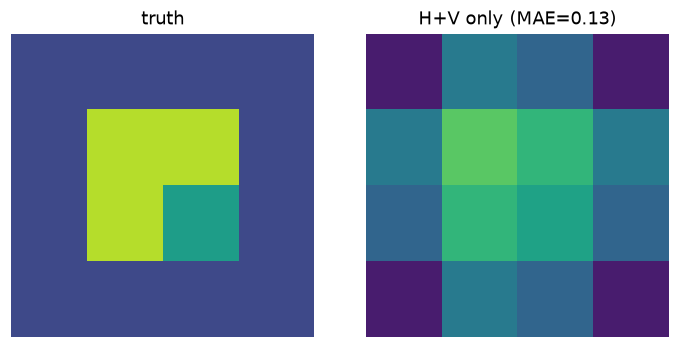

In [4]:
A_hv = build_A(H + V)
b_hv = A_hv @ mu_true.ravel()
print(f"A_hv shape = {A_hv.shape}  (equations x unknowns)")
print(f"rank(A_hv) = {np.linalg.matrix_rank(A_hv)}  <  16  -> underdetermined")

# Minimum-norm least-squares 'solution' is wrong because the system is deficient
mu_hv = np.linalg.lstsq(A_hv, b_hv, rcond=None)[0].reshape(N, N)
err_hv = np.abs(mu_hv - mu_true).mean()

fig, ax = plt.subplots(1, 2, figsize=(6.6, 3.2))
ax[0].imshow(mu_true, cmap="viridis", vmin=0, vmax=0.9); ax[0].set_title("truth"); ax[0].axis("off")
ax[1].imshow(mu_hv, cmap="viridis", vmin=0, vmax=0.9)
ax[1].set_title(f"H+V only (MAE={err_hv:.2f})"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 4. Add diagonal projections → (almost) full rank

Adding diagonal and anti-diagonal pencil beams injects most of the missing information: the combined
matrix jumps from rank 7 to **rank 15** (out of 16). A single degree of freedom remains invisible —
the **null-space "ghost"** image of Section 5. Because our phantom contains *no* ghost component, the
minimum-norm least-squares solution of $A\,\boldsymbol\mu=\mathbf{p}$ still recovers it essentially
exactly (to numerical precision). This is why real CT scanners acquire **many** angles — to drive the
rank all the way up and kill the ghost for *any* image.

A shape   = (22, 16)
rank(A)   = 15  of 16  (one null-space 'ghost' remains)
max |mu_hat - mu_true| = 6.11e-16  (phantom has no ghost component)


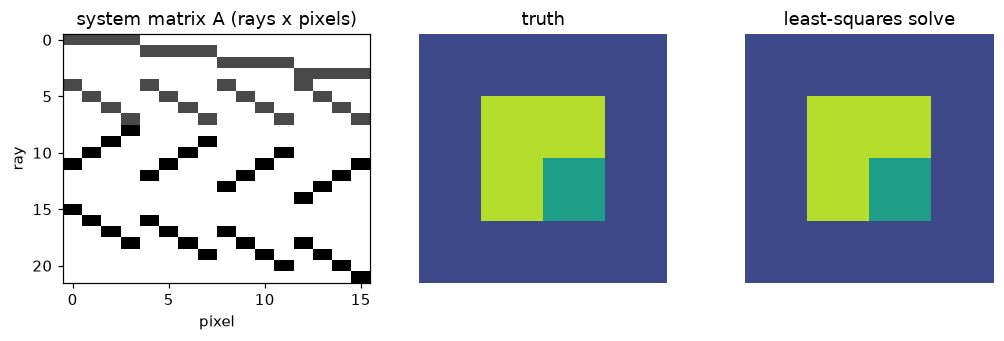

In [6]:
A = build_A(H + V + D + AD)
b = A @ mu_true.ravel()                      # noise-free line integrals
print(f"A shape   = {A.shape}")
print(f"rank(A)   = {np.linalg.matrix_rank(A)}  of 16  (one null-space 'ghost' remains)")

mu_hat = np.linalg.lstsq(A, b, rcond=None)[0].reshape(N, N)
err = np.abs(mu_hat - mu_true).max()
print(f"max |mu_hat - mu_true| = {err:.2e}  (phantom has no ghost component)")

fig, ax = plt.subplots(1, 3, figsize=(9.5, 3.2))
ax[0].imshow(A, cmap="gray_r", aspect="auto"); ax[0].set_title("system matrix A (rays x pixels)")
ax[0].set_xlabel("pixel"); ax[0].set_ylabel("ray")
ax[1].imshow(mu_true, cmap="viridis", vmin=0, vmax=0.9); ax[1].set_title("truth"); ax[1].axis("off")
ax[2].imshow(mu_hat, cmap="viridis", vmin=0, vmax=0.9)
ax[2].set_title("least-squares solve"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## 5. The null-space "ghost" — why one set of views isn't enough

With four beam orientations the rank is 15, so there is exactly **one** image that produces **zero**
signal on every ray — the **ghost**. Adding any multiple of it to a valid reconstruction leaves *all*
projections unchanged, so the problem is ambiguous for images that contain a ghost component. Here the
ghost is a checkerboard-like pattern; our phantom has no ghost component, which is why the solve above
was exact. Real scanners acquire many more angles to eliminate it entirely.

smallest singular value   = 3.30e-16  (=> rank deficiency)
max |A @ ghost|           = 3.40e-16  (invisible to all rays)
ghost . mu_true           = -4.16e-17  (phantom has none)


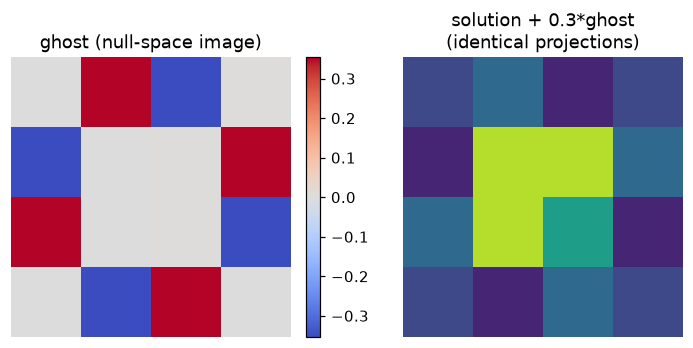

In [7]:
# The remaining null-space vector = the smallest-singular-value direction of A
_, s, vt = np.linalg.svd(A)
ghost = vt[-1].reshape(N, N)                 # the 'ghost' image invisible to every ray

print(f"smallest singular value   = {s[-1]:.2e}  (=> rank deficiency)")
print(f"max |A @ ghost|           = {np.abs(A @ ghost.ravel()).max():.2e}  (invisible to all rays)")
print(f"ghost . mu_true           = {float(ghost.ravel() @ mu_true.ravel()):.2e}  (phantom has none)")

# Any multiple of the ghost can be added to a solution without changing a single projection
mu_alias = mu_hat + 0.3 * ghost
fig, ax = plt.subplots(1, 2, figsize=(6.6, 3.2))
im0 = ax[0].imshow(ghost, cmap="coolwarm"); ax[0].set_title("ghost (null-space image)"); ax[0].axis("off")
plt.colorbar(im0, ax=ax[0], fraction=0.046)
ax[1].imshow(mu_alias, cmap="viridis", vmin=0, vmax=0.9)
ax[1].set_title("solution + 0.3*ghost\n(identical projections)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 6. Algebraic Reconstruction Technique (ART / Kaczmarz)

The EMI scanner did not invert a big matrix — it **iterated**. ART cycles through the equations one at
a time and, for each ray, nudges the current estimate so that ray's projection is satisfied
(**Kaczmarz** row-action update):
$$\boldsymbol\mu \leftarrow \boldsymbol\mu + \lambda\,\frac{p_k - \mathbf a_k^\top\boldsymbol\mu}
{\mathbf a_k^\top\mathbf a_k}\,\mathbf a_k,$$
where $\mathbf a_k$ is row $k$ of $A$ and $\lambda$ is a relaxation factor. Sweeping over all rays
repeatedly drives the estimate to the solution.

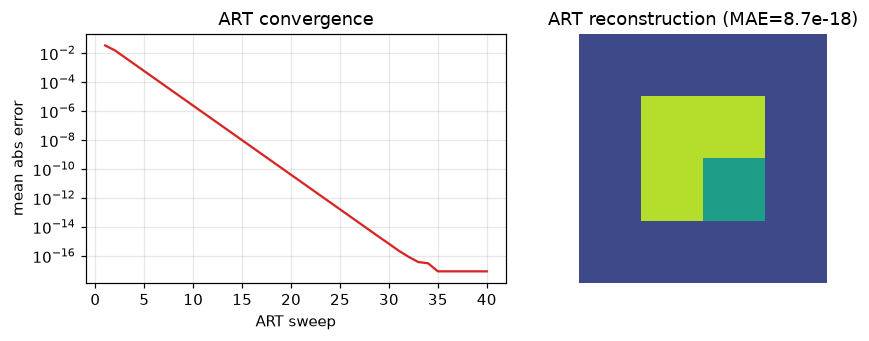

In [8]:
def art(A, b, n_sweeps=40, lam=1.0):
    mu = np.zeros(A.shape[1])
    history = []
    row_norm2 = (A * A).sum(axis=1)
    for _ in range(n_sweeps):
        for k in range(A.shape[0]):
            a = A[k]
            mu = mu + lam * (b[k] - a @ mu) / row_norm2[k] * a
        history.append(np.abs(mu.reshape(N, N) - mu_true).mean())
    return mu.reshape(N, N), history

mu_art, hist = art(A, b, n_sweeps=40, lam=1.0)

fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.2))
ax[0].semilogy(range(1, len(hist) + 1), hist, color="tab:red")
ax[0].set_xlabel("ART sweep"); ax[0].set_ylabel("mean abs error")
ax[0].set_title("ART convergence"); ax[0].grid(alpha=0.3)
ax[1].imshow(mu_art, cmap="viridis", vmin=0, vmax=0.9)
ax[1].set_title(f"ART reconstruction (MAE={hist[-1]:.1e})"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 7. Realistic photon (Poisson) noise

Real detectors count photons, so the exit intensity is $I\sim\text{Poisson}(I_0 e^{-p})$. The
measured projection $\hat p = -\ln(\hat I / I_0)$ is noisy, and the reconstruction degrades. More
incident photons $I_0$ (more dose) means less noise — the dose/quality trade-off from last week.

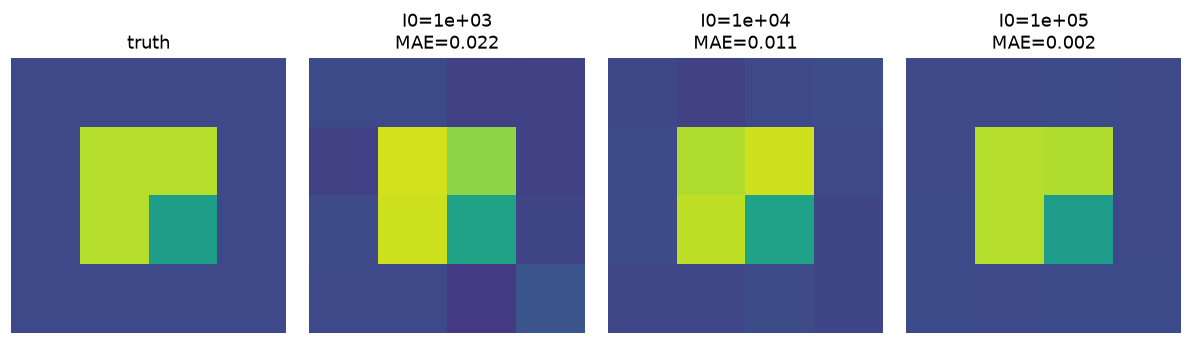

In [12]:
def noisy_reconstruction(I0_counts):
    p_clean = A @ mu_true.ravel()
    I_clean = I0_counts * np.exp(-p_clean)
    I_meas = rng.poisson(I_clean).astype(float)
    I_meas = np.clip(I_meas, 1.0, None)                 # avoid log(0)
    p_meas = -np.log(I_meas / I0_counts)
    mu = np.linalg.lstsq(A, p_meas, rcond=None)[0].reshape(N, N)
    return mu, np.abs(mu - mu_true).mean()

dose_levels = [1e3, 1e4, 1e5]
fig, ax = plt.subplots(1, len(dose_levels) + 1, figsize=(11, 3))
ax[0].imshow(mu_true, cmap="viridis", vmin=0, vmax=0.9); ax[0].set_title("truth"); ax[0].axis("off")
for k, I0c in enumerate(dose_levels, start=1):
    mu_n, mae = noisy_reconstruction(I0c)
    ax[k].imshow(mu_n, cmap="viridis", vmin=0, vmax=0.9)
    ax[k].set_title(f"I0={I0c:.0e}\nMAE={mae:.3f}"); ax[k].axis("off")
plt.tight_layout(); plt.show()

## Takeaways

- Each **pencil beam** is one **Beer–Lambert** equation; after taking the log it is a linear
  **weighted sum** of the pixel $\mu$'s (weights = path lengths). Stacking rays gives $A\boldsymbol\mu=\mathbf p$.
- A 4×4 image has **16 unknowns**, so we need ≥ 16 **independent** equations. Horizontal + vertical
  projections alone are badly **rank-deficient** (rank 7); **diagonal** views raise it to rank 15.
- With only four orientations, one **null-space "ghost"** image survives — invisible to every ray.
  Our phantom has no ghost component so it reconstructs exactly, but in general you must acquire
  **many angles** to drive the rank to 16 and remove the ambiguity.
- A **direct least-squares** solve and the **ART / Kaczmarz** iteration (the EMI-scanner approach)
  reach the same answer; ART simply sweeps over rays one at a time.
- **Photon noise** is Poisson in the counts; fewer incident photons (lower dose) → noisier
  projections → worse reconstruction — the same dose–quality trade-off seen in CT.
- This is a toy model of **iterative / filtered back-projection CT reconstruction**: real scanners use
  many hundreds of rays and angles, but the governing equation per ray is exactly the one above.